# OTT Streaming Content Trend Analysis
**Platforms:** Netflix, Amazon Prime, Disney+ Hotstar  
**Goal:** Explore genre mix, content ratings, release trends, regional mix and content format.

> **Dataset note:** The included CSV is a deterministic, synthetic practice catalog created for this internship exercise. It is not an official export from any streaming platform. Treat insights as a demonstration of the analysis workflow, not factual claims about platform catalogs.


In [13]:
# Google Drive mounting is omitted since the required dataset 'ott_content_catalog.csv'
# is already available locally in '/content/' and loads successfully below.
print("Local dataset is ready. Skipping Google Drive mount.")

Local dataset is ready. Skipping Google Drive mount.


## 1. Setup and load data

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# The dataset is already available in the current directory
csv_file = "/content/ott_content_catalog.csv"

try:
    df = pd.read_csv(csv_file)
    print("Successfully loaded dataset.")
except FileNotFoundError:
    # Fallback in case path differs
    csv_file = "ott_content_catalog.csv"
    df = pd.read_csv(csv_file)
    print("Successfully loaded dataset from fallback path.")

display(df.head())

Successfully loaded dataset.


,content_id,platform,title,content_type,release_year,date_added,country,genres,primary_genre,content_rating,duration_minutes,seasons,description
0,OTT0001,Disney+ Hotstar,Paper Kingdom 1,Movie,2002,2007-07-04,Mexico,"Animation, Drama",Animation,PG,103.0,NaN,A animation-focused movie set in Mexico.
1,OTT0002,Amazon Prime,Midnight Signal 2,Movie,2011,2014-11-23,India,"Family, Horror, Romance",Family,U,85.0,NaN,A family-focused movie set in India.
2,OTT0003,Amazon Prime,A Summer Promise 3,TV Show,2026,2026-06-14,Germany,Drama,Drama,PG-13,NaN,7.0,A drama-focused tv show set in Germany.
3,OTT0004,Netflix,Red Planet Files 4,TV Show,2024,2026-02-19,United States,"Drama, Romance",Drama,U/A 16+,NaN,3.0,A drama-focused tv show set in United States.
4,OTT0005,Netflix,Red Planet Files 5,Movie,2017,2021-06-22,France,Documentary,Documentary,U/A 13+,93.0,NaN,A documentary-focused movie set in France.


## 2. Data overview and cleaning

In [15]:
print("Shape:", df.shape)
print(df.info())
print("\\nMissing values:\\n", df.isna().sum())
print("Duplicate content IDs:", df["content_id"].duplicated().sum())

df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["platform"] = df["platform"].astype("category")
df["content_type"] = df["content_type"].astype("category")
df["primary_genre"] = df["primary_genre"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["content_rating"] = df["content_rating"].fillna("Not Rated")
df["genres"] = df["genres"].fillna("Unknown")
df = df.drop_duplicates(subset="content_id")
df.describe(include="all")


Shape: (600, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   content_id        600 non-null    object 
 1   platform          600 non-null    object 
 2   title             600 non-null    object 
 3   content_type      600 non-null    object 
 4   release_year      600 non-null    int64  
 5   date_added        600 non-null    object 
 6   country           600 non-null    object 
 7   genres            600 non-null    object 
 8   primary_genre     600 non-null    object 
 9   content_rating    600 non-null    object 
 10  duration_minutes  407 non-null    float64
 11  seasons           193 non-null    float64
 12  description       600 non-null    object 
dtypes: float64(2), int64(1), object(10)
memory usage: 61.1+ KB
None
\nMissing values:\n content_id            0
platform              0
title                 0
content_type

,content_id,platform,title,content_type,release_year,date_added,country,genres,primary_genre,content_rating,duration_minutes,seasons,description
count,600,600,600,600,600.000000,600,600,600,600,600,407.000000,193.000000,600
unique,600,3,600,2,NaN,NaN,12,202,12,10,NaN,NaN,205
top,OTT0001,Netflix,Paper Kingdom 1,Movie,NaN,NaN,India,Reality,Reality,U/A 16+,NaN,NaN,A crime-focused movie set in United States.
freq,1,233,1,407,NaN,NaN,152,32,63,87,NaN,NaN,15
mean,NaN,NaN,NaN,NaN,2012.228333,2015-07-07 00:07:12,NaN,NaN,NaN,NaN,111.009828,4.466321,NaN
min,NaN,NaN,NaN,NaN,2000.000000,2000-02-10 00:00:00,NaN,NaN,NaN,NaN,37.000000,1.000000,NaN
25%,NaN,NaN,NaN,NaN,2006.000000,2009-02-12 12:00:00,NaN,NaN,NaN,NaN,92.000000,2.000000,NaN
50%,NaN,NaN,NaN,NaN,2012.000000,2015-07-06 12:00:00,NaN,NaN,NaN,NaN,112.000000,5.000000,NaN
75%,NaN,NaN,NaN,NaN,2018.000000,2022-02-13 18:00:00,NaN,NaN,NaN,NaN,129.000000,7.000000,NaN
max,NaN,NaN,NaN,NaN,2026.000000,2026-12-26 00:00:00,NaN,NaN,NaN,NaN,192.000000,8.000000,NaN


## 3. KPI summary

In [16]:
kpis = pd.DataFrame({
    "Metric": ["Total titles", "Movies", "TV Shows", "Platforms", "Countries"],
    "Value": [len(df), (df.content_type == "Movie").sum(),
              (df.content_type == "TV Show").sum(), df.platform.nunique(),
              df.country.nunique()]
})
kpis


,Metric,Value
0,Total titles,600
1,Movies,407
2,TV Shows,193
3,Platforms,3
4,Countries,12


## 4. Exploratory data visualizations (8 charts)

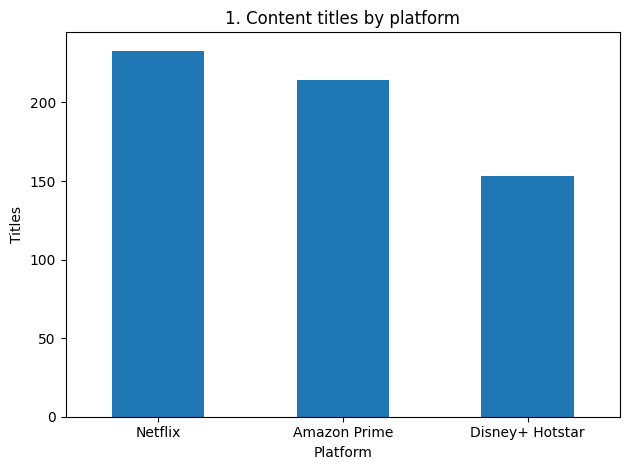

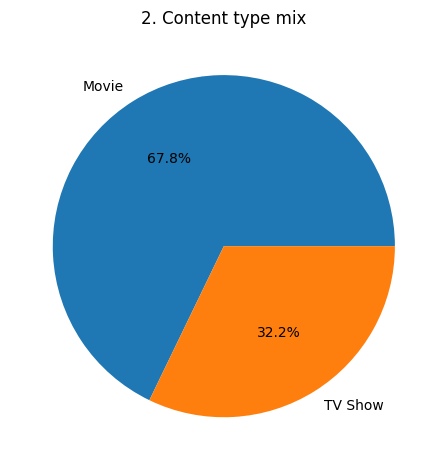

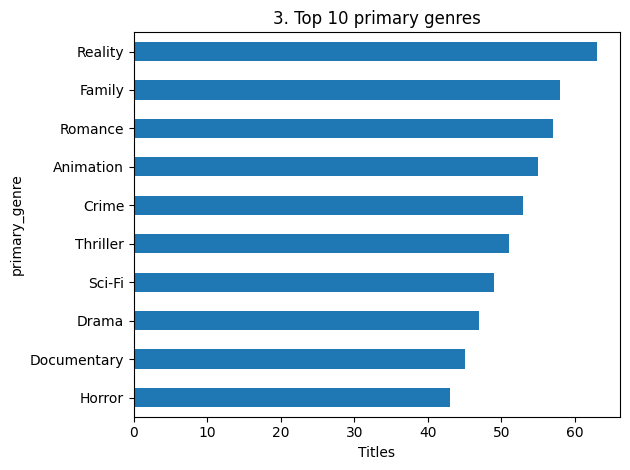

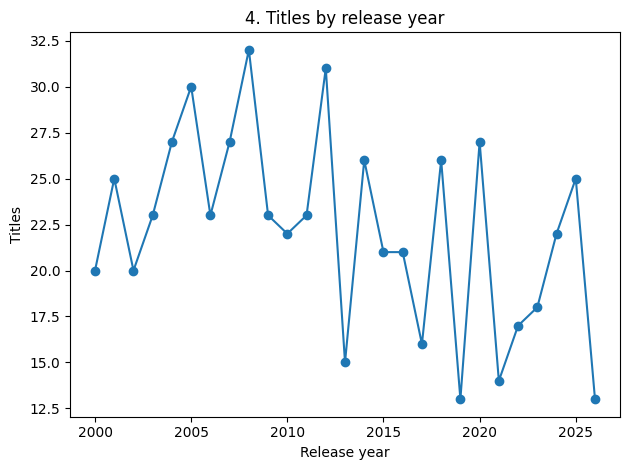

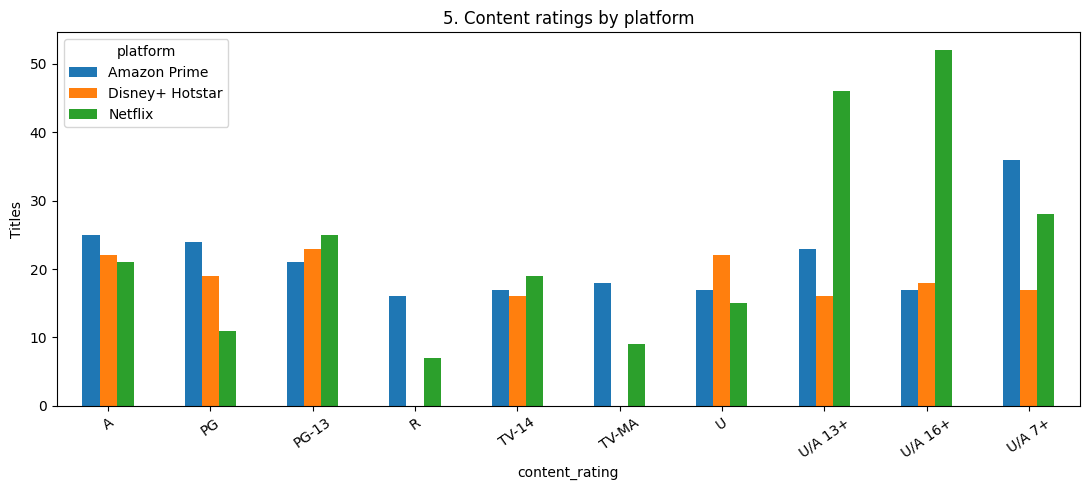

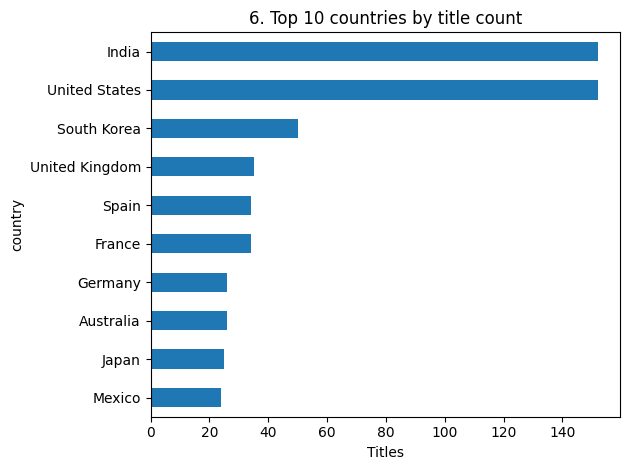

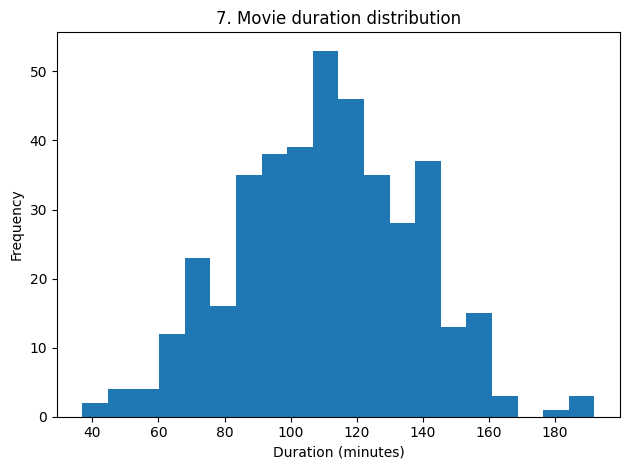

/tmp/ipykernel_1493/3206513659.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  (df[df.content_type == "Movie"].groupby("platform")["duration_minutes"].mean()


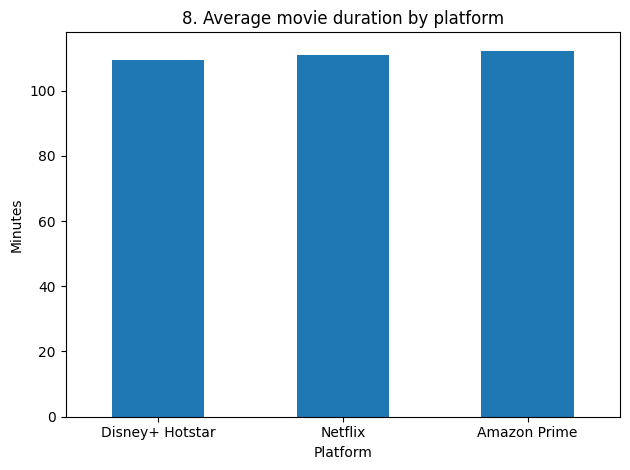

In [17]:
# Chart 1: Titles by platform
df["platform"].value_counts().plot(kind="bar", title="1. Content titles by platform", ylabel="Titles", xlabel="Platform", rot=0)
plt.tight_layout(); plt.show()

# Chart 2: Movie vs TV show mix
df["content_type"].value_counts().plot(kind="pie", autopct="%1.1f%%", title="2. Content type mix", ylabel="")
plt.tight_layout(); plt.show()

# Chart 3: Top primary genres
df["primary_genre"].value_counts().head(10).sort_values().plot(kind="barh", title="3. Top 10 primary genres", xlabel="Titles")
plt.tight_layout(); plt.show()

# Chart 4: Release trend by year
df.groupby("release_year").size().sort_index().plot(kind="line", marker="o", title="4. Titles by release year", xlabel="Release year", ylabel="Titles")
plt.tight_layout(); plt.show()

# Chart 5: Ratings by platform
rating_platform = pd.crosstab(df["content_rating"], df["platform"])
rating_platform.plot(kind="bar", figsize=(11,5), title="5. Content ratings by platform", ylabel="Titles", rot=35)
plt.tight_layout(); plt.show()

# Chart 6: Top countries
df["country"].value_counts().head(10).sort_values().plot(kind="barh", title="6. Top 10 countries by title count", xlabel="Titles")
plt.tight_layout(); plt.show()

# Chart 7: Movie duration distribution
movie_durations = df.loc[df.content_type == "Movie", "duration_minutes"].dropna()
movie_durations.plot(kind="hist", bins=20, title="7. Movie duration distribution", xlabel="Duration (minutes)", ylabel="Frequency")
plt.tight_layout(); plt.show()

# Chart 8: Average movie duration by platform
(df[df.content_type == "Movie"].groupby("platform")["duration_minutes"].mean()
 .sort_values().plot(kind="bar", title="8. Average movie duration by platform", ylabel="Minutes", xlabel="Platform", rot=0))
plt.tight_layout(); plt.show()


## 5. Core business questions

In [18]:
# Genre mix by platform
genre_by_platform = pd.crosstab(df["primary_genre"], df["platform"])
display(genre_by_platform)

# Regional content mix
regional_mix = pd.crosstab(df["country"], df["platform"])
display(regional_mix)

# Release-year trend by platform
display(df.pivot_table(index="release_year", columns="platform", values="content_id",
                       aggfunc="count", fill_value=0).tail(15))

# Average duration and average seasons
display(df.groupby(["platform", "content_type"], observed=False)
        .agg(title_count=("content_id","count"),
             avg_movie_minutes=("duration_minutes","mean"),
             avg_seasons=("seasons","mean")).round(2))


platform,Amazon Prime,Disney+ Hotstar,Netflix
primary_genre,,,
Action,10,5,22
Animation,16,14,25
Comedy,8,11,23
Crime,23,13,17
Documentary,13,13,19
Drama,14,14,19
Family,28,12,18
Horror,16,11,16
Reality,26,15,22


platform,Amazon Prime,Disney+ Hotstar,Netflix
country,,,
Australia,7,9,10
Canada,7,5,7
France,12,7,15
Germany,9,5,12
India,60,36,56
Japan,9,7,9
Mexico,10,7,7
South Korea,16,12,22
Spain,8,9,17


/tmp/ipykernel_1493/691993816.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  display(df.pivot_table(index="release_year", columns="platform", values="content_id",


platform,Amazon Prime,Disney+ Hotstar,Netflix
release_year,,,
2012,11,10,10
2013,4,4,7
2014,11,9,6
2015,4,10,7
2016,6,5,10
2017,7,1,8
2018,9,6,11
2019,6,2,5
2020,9,6,12


title_count  avg_movie_minutes  avg_seasons
platform        content_type                                             
Amazon Prime    Movie                 145             112.26          NaN
                TV Show                69                NaN         4.58
Disney+ Hotstar Movie                 107             109.47          NaN
                TV Show                46                NaN         4.41
Netflix         Movie                 155             110.91          NaN
                TV Show                78                NaN         4.40

## 6. Three evidence-led insights (generate from this dataset)

In [19]:
top_genre = df["primary_genre"].value_counts().idxmax()
top_country = df["country"].value_counts().idxmax()
movie_avg = df.loc[df.content_type == "Movie", "duration_minutes"].mean()
platform_counts = df["platform"].value_counts()
print(f"1. {top_genre} is the largest primary-genre group in this sample ({df.primary_genre.value_counts().max()} titles).")
print(f"2. {top_country} contributes the most titles in this sample ({df.country.value_counts().max()} titles).")
print(f"3. The sample's average movie duration is {movie_avg:.1f} minutes; compare this by platform before making programming decisions.")
print("\\nPlatform catalog counts:\\n", platform_counts)


1. Reality is the largest primary-genre group in this sample (63 titles).
2. India contributes the most titles in this sample (152 titles).
3. The sample's average movie duration is 111.0 minutes; compare this by platform before making programming decisions.
\nPlatform catalog counts:\n platform
Netflix            233
Amazon Prime       214
Disney+ Hotstar    153
Name: count, dtype: int64


## 7. Export cleaned data and summary tables

In [20]:
df.to_csv("ott_content_catalog_cleaned.csv", index=False)
genre_by_platform.to_csv("genre_by_platform.csv")
regional_mix.to_csv("regional_mix.csv")
print("Exported cleaned catalog and summary tables.")


Exported cleaned catalog and summary tables.


## 8. Conclusion

Use the visualizations to identify catalog concentration, genre opportunities, regional representation and runtime patterns. Before making real business decisions, repeat the analysis with verified, current catalog data and a consistent definition of each platform's available titles.